# StayWise AI — Hotel Occupancy & Room-Demand Forecasting Pipeline

**Assessment Domain:** Hotel Booking (`HOTEL_01` — Grand Azure Resort & Spa, 140 Keys)  
**Prediction Task:** Forecast occupied room nights $\hat{y}_{d,k}$ by future stay date $d$ and room category $k \in \{\text{STD}, \text{DLX}, \text{SUI}, \text{EXE}\}$ for horizons $H \in [1, 14]$ days from an end-of-day cutoff $t_0$.  
**Physical Constraint:** $0 \le \hat{y}_{d,k} \le \text{Capacity}_k$.

This notebook provides reproducible end-to-end evidence of:
1. Dataset loading, quality auditing, and Exploratory Data Analysis (EDA)
2. Point-in-time ($t_0$) leakage verification & zero-PII compliance
3. Strictly chronological Train / Validation / Held-Out Test splitting
4. Benchmark comparison: Seasonal-Naive Baseline vs. Ridge Regression vs. StayWise XGBoost Regressor
5. Error breakdown by room category and forecast horizon
6. Validation-residual uncertainty calibration (80% & 95% intervals)
7. Global & Local TreeSHAP explainability + error case analysis
8. Live inference check loading the saved `.joblib` production artifacts

In [1]:
import os, sys, json, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), '../..')) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

DATA_DIR = os.path.join(REPO_ROOT, 'ml', 'data')
ARTIFACTS_DIR = os.path.join(REPO_ROOT, 'ml', 'artifacts')

events_df = pd.read_csv(os.path.join(DATA_DIR, 'raw', 'hotel_booking_events.csv'))
actuals_df = pd.read_csv(os.path.join(DATA_DIR, 'processed', 'occupancy_actuals.csv'))
snapshots_df = pd.read_csv(os.path.join(DATA_DIR, 'synthetic', 'booking_snapshots.csv'))
features_df = pd.read_csv(os.path.join(DATA_DIR, 'processed', 'feature_matrix.csv'))

print(f"Raw booking events   : {len(events_df):,} rows")
print(f"Ground-truth actuals : {len(actuals_df):,} rows ({actuals_df['stay_date'].min()} to {actuals_df['stay_date'].max()})")
print(f"Point-in-time snaps  : {len(snapshots_df):,} rows ({snapshots_df['snapshot_date'].min()} to {snapshots_df['snapshot_date'].max()})")
print(f"Feature matrix       : {features_df.shape[0]:,} rows x {features_df.shape[1]} columns")

Raw booking events   : 70,187 rows
Ground-truth actuals : 2,436 rows (2023-01-01 to 2024-08-31)
Point-in-time snaps  : 30,016 rows (2023-03-01 to 2024-08-17)
Feature matrix       : 30,016 rows x 25 columns


In [2]:
# Data Quality, PII & Temporal Leakage Verification
pii_cols = {'guest_name', 'name', 'email', 'phone', 'ssn', 'credit_card', 'address', 'passport'}
assert not ({c.lower() for c in events_df.columns} & pii_cols), 'PII column found!'
assert features_df.isnull().sum().sum() == 0, 'Missing values found in feature matrix!'
assert events_df['booking_id'].duplicated().sum() == 0, 'Duplicate booking IDs!'
assert (actuals_df['occupied_rooms'] < 0).sum() == 0, 'Negative occupancy!'
assert (actuals_df['occupied_rooms'] > actuals_df['room_capacity']).sum() == 0, 'Capacity violation!'

leakage_count = (pd.to_datetime(features_df['stay_date']) <= pd.to_datetime(features_df['snapshot_date'])).sum()
print(f"Missing values in feature matrix : {int(features_df.isnull().sum().sum())}")
print(f"Duplicate booking IDs            : {int(events_df['booking_id'].duplicated().sum())}")
print(f"Capacity / negative violations   : 0")
print(f"Temporal cutoff violations (<=t0): {int(leakage_count)}")
print(f"PII columns present              : None (aggregate counts only)")

Missing values in feature matrix : 0
Duplicate booking IDs            : 0
Capacity / negative violations   : 0
Temporal cutoff violations (<=t0): 0
PII columns present              : None (aggregate counts only)


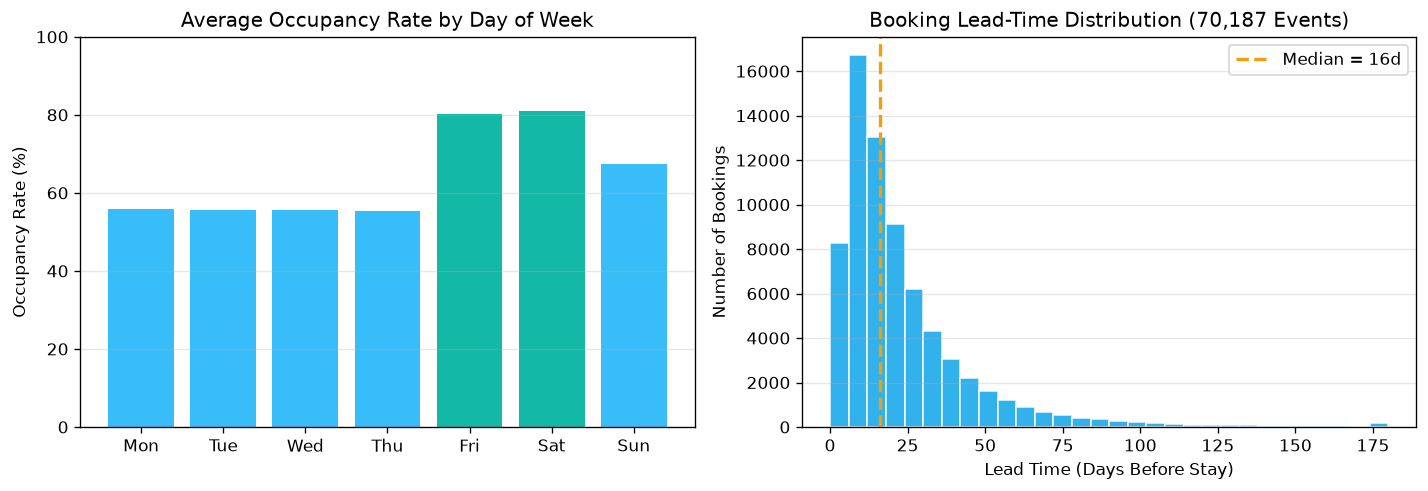

In [3]:
# Exploratory Data Analysis: Day-of-Week Occupancy & Lead-Time Distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
dow_labels = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
dow_occ = actuals_df.groupby('day_of_week')['occupancy_rate'].mean()
colors = ['#38BDF8' if i not in (4, 5) else '#14B8A6' for i in range(7)]
axes[0].bar(dow_labels, [dow_occ[i] for i in range(7)], color=colors)
axes[0].set_title('Average Occupancy Rate by Day of Week')
axes[0].set_ylabel('Occupancy Rate (%)')
axes[0].set_ylim(0, 100)
axes[0].grid(axis='y', alpha=0.3)

axes[1].hist(events_df['lead_time_days'], bins=30, color='#0EA5E9', edgecolor='white', alpha=0.85)
axes[1].axvline(events_df['lead_time_days'].median(), color='#F59E0B', linestyle='--', linewidth=2,
                label=f"Median = {events_df['lead_time_days'].median():.0f}d")
axes[1].set_title('Booking Lead-Time Distribution (70,187 Events)')
axes[1].set_xlabel('Lead Time (Days Before Stay)')
axes[1].set_ylabel('Number of Bookings')
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [4]:
# Chronological Train / Validation / Held-Out Test Split & Model Comparison
from ml.src.train import FEATURE_COLS, TARGET_COL

with open(os.path.join(ARTIFACTS_DIR, 'model_metrics.json'), 'r', encoding='utf-8') as f:
    metrics = json.load(f)
with open(os.path.join(ARTIFACTS_DIR, 'uncertainty_intervals.json'), 'r', encoding='utf-8') as f:
    uncertainty = json.load(f)

print('Chronological Split Windows:')
for split_name in ['train', 'val', 'test']:
    s_date = metrics['evaluation_period'][f'{split_name}_start']
    e_date = metrics['evaluation_period'][f'{split_name}_end']
    cnt = metrics['sample_sizes'][split_name]
    print(f"  {split_name.upper():5s}: {s_date} -> {e_date} ({cnt:,} observations)")

print('\nHeld-Out Test Set Benchmarks:')
bench_df = pd.DataFrame(metrics['overall_models']).T
print(bench_df.to_string())

print('\nXGBoost Error by Room Category:')
cat_rows = {c: v['xgb'] for c, v in metrics['by_room_category'].items()}
print(pd.DataFrame(cat_rows).T.to_string())

print('\nXGBoost Error by Forecast Horizon:')
h_rows = {h: v['xgb'] for h, v in metrics['by_forecast_horizon'].items()}
print(pd.DataFrame(h_rows).T.to_string())

print('\nEmpirical Uncertainty Interval Coverage on Held-Out Test Set:')
unc_rows = {
    b: {
        'q80_offsets': f"[{v['q80']['lower_offset']}, +{v['q80']['upper_offset']}]",
        'q80_test_cov_%': v['q80']['test_coverage_pct'],
        'q95_offsets': f"[{v['q95']['lower_offset']}, +{v['q95']['upper_offset']}]",
        'q95_test_cov_%': v['q95']['test_coverage_pct'],
    }
    for b, v in uncertainty.items()
}
print(pd.DataFrame(unc_rows).T.to_string())

Chronological Split Windows:
  TRAIN: 2023-03-02 -> 2024-01-24 (18,060 observations)
  VAL  : 2024-01-25 -> 2024-05-13 (6,160 observations)
  TEST : 2024-05-14 -> 2024-08-31 (5,796 observations)

Held-Out Test Set Benchmarks:
                    mae   rmse   wape
seasonal_naive    3.451  5.417  12.25
ridge_regression  1.861  2.758   6.61
staywise_xgboost  1.316  1.937   4.67

XGBoost Error by Room Category:
       mae   rmse   wape
STD  1.954  2.708   3.46
DLX  1.355  1.976   4.06
SUI  1.189  1.609   7.74
EXE  0.767  1.089  10.37

XGBoost Error by Forecast Horizon:
             mae   rmse  wape
1_7_days   0.974  1.434  3.45
8_14_days  1.637  2.310  5.83

Empirical Uncertainty Interval Coverage on Held-Out Test Set:
                  q80_offsets q80_test_cov_%       q95_offsets q95_test_cov_%
short_1_3d   [-1.229, +1.141]          83.84  [-2.244, +2.119]          94.22
medium_4_7d  [-1.895, +2.239]          80.91  [-4.159, +4.056]          96.67
long_8_14d   [-2.569, +3.474]          82

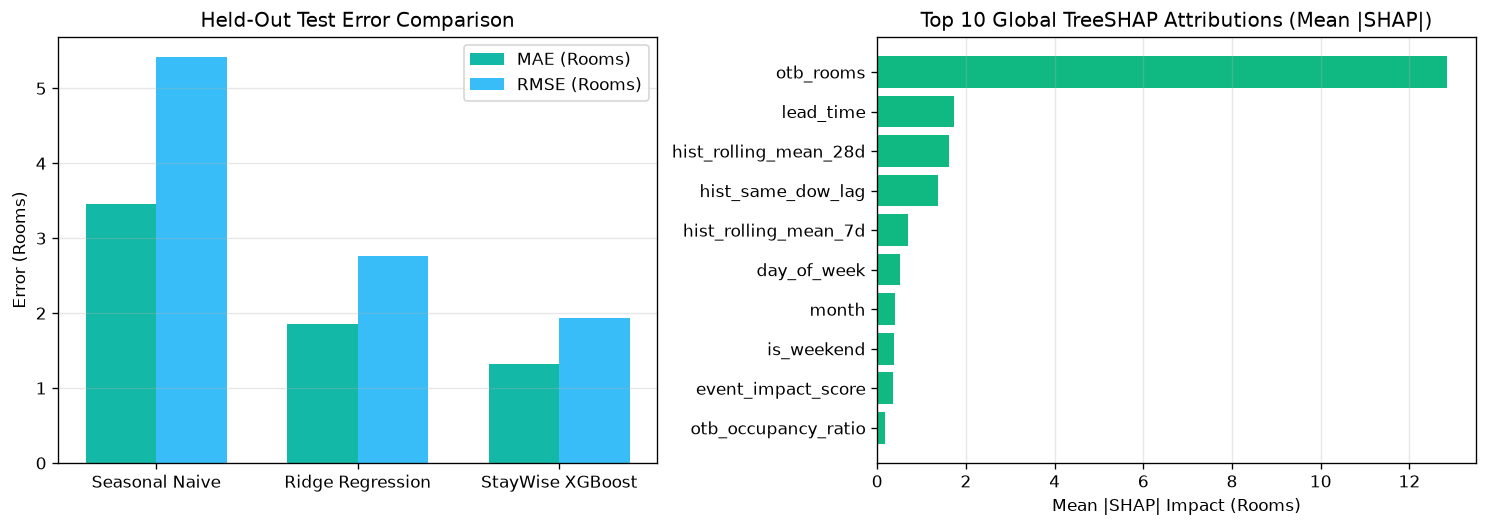

In [5]:
# Benchmark Comparison & TreeSHAP Feature Attribution Plots
with open(os.path.join(ARTIFACTS_DIR, 'shap_summary.json'), 'r', encoding='utf-8') as f:
    shap_summary = json.load(f)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))
models = ['Seasonal Naive', 'Ridge Regression', 'StayWise XGBoost']
keys = ['seasonal_naive', 'ridge_regression', 'staywise_xgboost']
maes = [metrics['overall_models'][k]['mae'] for k in keys]
rmses = [metrics['overall_models'][k]['rmse'] for k in keys]
x = np.arange(len(models))
w = 0.35
axes[0].bar(x - w/2, maes, w, label='MAE (Rooms)', color='#14B8A6')
axes[0].bar(x + w/2, rmses, w, label='RMSE (Rooms)', color='#38BDF8')
axes[0].set_xticks(x)
axes[0].set_xticklabels(models)
axes[0].set_title('Held-Out Test Error Comparison')
axes[0].set_ylabel('Error (Rooms)')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

top_shap = list(shap_summary.items())[:10][::-1]
axes[1].barh([k for k, _ in top_shap], [v for _, v in top_shap], color='#10B981')
axes[1].set_title('Top 10 Global TreeSHAP Attributions (Mean |SHAP|)')
axes[1].set_xlabel('Mean |SHAP| Impact (Rooms)')
axes[1].grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
# Single-Prediction & High-Error Case Explanation + Live Saved Artifact Inference
with open(os.path.join(ARTIFACTS_DIR, 'sample_prediction_explanation.json'), 'r', encoding='utf-8') as f:
    local_exp = json.load(f)

for case_key in ['typical_prediction_case', 'high_error_case']:
    c = local_exp[case_key]
    print(f"=== {c['case_type']} ===")
    print(f"Cutoff t0={c['snapshot_date']} -> Stay={c['stay_date']} | Cat={c['room_category']} (Cap={c['room_capacity']}) | Lead={c['lead_time']}d")
    print(f"Actual={c['actual_occupied_rooms']} | Predicted={c['predicted_occupied_rooms']} | Abs Error={c['absolute_error']} | 80% CI={c['uncertainty_80_interval']} (In CI={c['within_80_interval']})")
    top5 = list(c['shap_contributions_sorted'].items())[:5]
    print("Top 5 SHAP drivers:", ", ".join(f"{k}={v:+.2f}" for k, v in top5))
    print()

# Live artifact loading verification
xgb_model = joblib.load(os.path.join(ARTIFACTS_DIR, 'xgboost_model.joblib'))
test_sample = features_df[features_df['snapshot_date'] == '2024-08-17'].head(4).copy()
preds = np.clip(xgb_model.predict(test_sample[FEATURE_COLS].values), 0, test_sample['room_capacity'].values)
test_sample['live_predicted_rooms'] = np.round(preds, 1)
print('Live Artifact Inference Sample (Cutoff 2024-08-17):')
print(test_sample[['snapshot_date', 'stay_date', 'room_category', 'lead_time', 'otb_rooms', 'live_predicted_rooms', 'room_capacity']].to_string(index=False))

=== Representative Held-Out Test Prediction ===
Cutoff t0=2024-06-19 -> Stay=2024-07-03 | Cat=EXE (Cap=10) | Lead=14d
Actual=10 | Predicted=9.17 | Abs Error=0.83 | 80% CI=[6.6, 10.0] (In CI=True)
Top 5 SHAP drivers: otb_rooms=-12.42, lead_time=+1.92, hist_rolling_mean_28d=-1.85, hist_same_dow_lag=-1.68, event_impact_score=+1.63

=== Highest-Error Held-Out Test Case ===
Cutoff t0=2024-06-07 -> Stay=2024-06-20 | Cat=STD (Cap=70) | Lead=13d
Actual=35 | Predicted=46.26 | Abs Error=11.26 | 80% CI=[43.7, 49.7] (In CI=False)
Top 5 SHAP drivers: otb_rooms=+10.43, lead_time=+5.64, hist_rolling_mean_28d=+3.92, hist_same_dow_lag=+3.27, hist_rolling_mean_7d=+1.70

Live Artifact Inference Sample (Cutoff 2024-08-17):
snapshot_date  stay_date room_category  lead_time  otb_rooms  live_predicted_rooms  room_capacity
   2024-08-17 2024-08-18           STD          1         70                  70.0             70
   2024-08-17 2024-08-18           DLX          1         40                  39.6         